# Clean Atlas registrations and AFDC stations to ZIP level

**Inputs** (in `data/raw/`, never edited): the Atlas EV registrations CSV and the AFDC alternative fuel stations CSV.
**Outputs** (in `data/processed/`): `atlas_zip.csv`, `afdc_zip.csv`, and `cleaning_log.json` (the counts to copy into the provenance log and data dictionary).

Every filter is printed, so the numbers you cite in the writeup come from this notebook. Run top to bottom.

## 0. Setup and paths

In [1]:
from pathlib import Path
import json
import tempfile
import pandas as pd

pd.set_option("display.width", 200)
pd.set_option("display.max_columns", 30)

def find_root(start=None):
    """Walk up from the working directory until a folder containing data/ is found."""
    start = Path.cwd() if start is None else Path(start)
    for p in [start, *start.parents]:
        if (p / "data").is_dir():
            return p
    raise FileNotFoundError(f"No data/ folder found at or above {start}")

ROOT = find_root()
RAW = ROOT / "data" / "raw"
PROC = ROOT / "data" / "processed"
PROC.mkdir(parents=True, exist_ok=True)

def pick(pattern):
    matches = sorted(RAW.glob(pattern))
    if not matches:
        raise FileNotFoundError(f"No file matching {pattern} in {RAW}")
    if len(matches) > 1:
        print(f"WARNING: several files match {pattern}; using {matches[0].name}: {[m.name for m in matches]}")
    return matches[0]

ATLAS_RAW = pick("CO_EV_Registrations*.csv")
AFDC_RAW = pick("alt_fuel_stations*.csv")
LOG = {"atlas_file": ATLAS_RAW.name, "afdc_file": AFDC_RAW.name}

print("repo root:", ROOT)
print("Atlas file:", ATLAS_RAW.name)
print("AFDC file: ", AFDC_RAW.name)

repo root: /Users/abdullahbharde/CU Boulder/Data Mining/Group Project/Colorado-EV-Charging-Analysis
Atlas file: CO_EV_Registrations_10_2026.csv
AFDC file:  alt_fuel_stations (Oct 15 2026).csv


## 1. Atlas registrations

**Unit of observation (raw):** one row is a group of vehicles with the same ZIP, registration date, make, model, model year, drivetrain, weight class and DMV snapshot. `Vehicle Count` is the number of vehicles in the group, so sum it; do not count rows.
The file stacks monthly DMV snapshots, so we keep **only the latest snapshot**. Otherwise the same vehicles are counted once per month.

In [2]:
def read_atlas(path):
    """Read the Atlas CSV. If the download was truncated mid-row, drop the broken last line
    in a temporary copy (the raw file is untouched) and say so. Re-downloading is better."""
    try:
        return pd.read_csv(path, dtype=str, low_memory=False), False
    except pd.errors.ParserError as err:
        print("ParserError on first read:", str(err)[:120])
        print("The file is probably truncated. Dropping the final partial line in a temp copy.")
        with open(path, encoding="utf-8", newline="") as src:
            lines = src.readlines()
        tmp = Path(tempfile.gettempdir()) / "atlas_repaired.csv"
        with open(tmp, "w", encoding="utf-8", newline="") as dst:
            dst.writelines(lines[:-1])
        return pd.read_csv(tmp, dtype=str, low_memory=False), True

atlas, repaired = read_atlas(ATLAS_RAW)
LOG["atlas_repaired_truncated_tail"] = repaired

needed = ["ZIP Code", "Registration Date", "Vehicle Model Year", "Drivetrain Type",
          "Vehicle GVWR Category", "Vehicle Count", "DMV Snapshot (Date)", "Latest DMV Snapshot Flag"]
missing_cols = [c for c in needed if c not in atlas.columns]
assert not missing_cols, f"Atlas file is missing expected columns: {missing_cols}"

print("raw rows:", len(atlas))
print("columns:", atlas.columns.tolist())
LOG["atlas_raw_rows"] = len(atlas)

raw rows: 5970397
columns: ['State', 'ZIP Code', 'Registration Date', 'Vehicle Make', 'Vehicle Model', 'Vehicle Model Year', 'Drivetrain Type', 'Vehicle GVWR Class', 'Vehicle GVWR Category', 'Vehicle Count', 'DMV Snapshot ID', 'DMV Snapshot (Date)', 'Latest DMV Snapshot Flag']


In [3]:
# Parse types
atlas["Vehicle Count"] = pd.to_numeric(atlas["Vehicle Count"], errors="coerce")
atlas["snap"] = pd.to_datetime(
    atlas["DMV Snapshot (Date)"].str.extract(r"\((.*)\)")[0], format="%m/%d/%Y", errors="coerce")
atlas["reg_date"] = pd.to_datetime(atlas["Registration Date"], errors="coerce")

print("missing/non-numeric Vehicle Count:", atlas["Vehicle Count"].isna().sum())
print("unparsed snapshot dates:         ", atlas["snap"].isna().sum())
print("unparsed registration dates:     ", atlas["reg_date"].isna().sum())

atlas = atlas.dropna(subset=["Vehicle Count", "snap"]).copy()
atlas["Vehicle Count"] = atlas["Vehicle Count"].astype(int)

# Registration-date window per snapshot (documents how the date field behaves)
win = atlas.groupby("snap")["reg_date"].agg(["min", "max"])
win["window_months"] = ((win["max"] - win["min"]).dt.days / 30.4).round(1)
print("\nSnapshots in file:", len(win))
win.tail(8)

missing/non-numeric Vehicle Count: 0
unparsed snapshot dates:          0
unparsed registration dates:      0



Snapshots in file: 90


,min,max,window_months
snap,,,
2025-12-07,2016-09-01,2025-12-01,111.1
2026-01-07,2016-09-01,2026-01-01,112.1
2026-02-07,2016-09-01,2026-02-01,113.2
2026-03-07,2016-09-01,2026-03-01,114.1
2026-04-07,2016-09-01,2026-04-01,115.1
2026-05-07,2016-09-01,2026-05-01,116.1
2026-06-07,2016-09-01,2026-06-01,117.1
2026-07-07,2016-09-01,2026-07-01,118.1


In [4]:
# Keep the latest snapshot only
latest_date = atlas["snap"].max()
latest = atlas[atlas["snap"] == latest_date].copy()

flag_dates = atlas.loc[atlas["Latest DMV Snapshot Flag"].astype(str).str.lower() == "true", "snap"].unique()
print("latest snapshot by date:", latest_date.date())
print("snapshot(s) carrying the 'latest' flag:", [pd.Timestamp(d).date() for d in flag_dates])
print("rows in latest snapshot:", len(latest), "| vehicles:", latest["Vehicle Count"].sum())
print("registration dates in latest snapshot:", latest["reg_date"].min().date(), "to", latest["reg_date"].max().date())
print("oldest model years present:", sorted(latest["Vehicle Model Year"].dropna().unique())[:6])

print("\nDrivetrain types in latest snapshot:")
print(latest["Drivetrain Type"].value_counts(dropna=False))
print("\nWeight classes in latest snapshot (vehicles):")
print(latest.groupby("Vehicle GVWR Category", dropna=False)["Vehicle Count"].sum())

LOG.update({
    "atlas_latest_snapshot": str(latest_date.date()),
    "atlas_latest_snapshot_vehicles_all_classes": int(latest["Vehicle Count"].sum()),
})

latest snapshot by date: 2026-07-07
snapshot(s) carrying the 'latest' flag: [datetime.date(2026, 7, 7)]
rows in latest snapshot: 161053 | vehicles: 215105
registration dates in latest snapshot: 2016-09-01 to 2026-07-01
oldest model years present: ['1990', '1991', '1992', '1993', '1994', '1996']

Drivetrain types in latest snapshot:
Drivetrain Type
BEV     115207
PHEV     45846
Name: count, dtype: int64

Weight classes in latest snapshot (vehicles):
Vehicle GVWR Category
Heavy-Duty Vehicle (Class 7-8)           141
Light-Duty (Class 1-2A)               202639
Medium-Duty Vehicle (Class 2B - 6)     10685
Unknown                                 1640
Name: Vehicle Count, dtype: int64


In [5]:
# All vehicle classes (team Milestone 2 decision: scope = all classes).
# Light-duty is still computed and reported as a diagnostic, but the ZIP table
# that feeds downstream analysis counts every class so it matches src/prepare_and_eda.py.
all_cls = latest.copy()
ld = latest[latest["Vehicle GVWR Category"].str.startswith("Light-Duty", na=False)]
print("all-class vehicles:", all_cls["Vehicle Count"].sum(),
      "| light-duty subtotal (diagnostic):", ld["Vehicle Count"].sum(),
      "| non-light-duty:", all_cls["Vehicle Count"].sum() - ld["Vehicle Count"].sum())
# ZIPs as 5-character strings
all_cls = all_cls.copy()
all_cls["zip"] = all_cls["ZIP Code"].astype(str).str.strip().str[:5]
bad_zip = ~all_cls["zip"].str.fullmatch(r"\d{5}")
print("rows with invalid ZIP (dropped):", bad_zip.sum(), "| vehicles:", all_cls.loc[bad_zip, "Vehicle Count"].sum())
all_cls = all_cls[~bad_zip]
# One row per ZIP
piv = all_cls.pivot_table(index="zip", columns="Drivetrain Type", values="Vehicle Count",
                          aggfunc="sum", fill_value=0)
for c in ["BEV", "PHEV"]:
    if c not in piv.columns:
        piv[c] = 0
other = [c for c in piv.columns if c not in ("BEV", "PHEV")]
if other:
    print("NOTE: other drivetrain types found, combined into other_ev:", other)
atlas_zip = piv[["BEV", "PHEV"]].copy()
atlas_zip["other_ev"] = piv[other].sum(axis=1) if other else 0
atlas_zip["total_ev"] = atlas_zip[["BEV", "PHEV", "other_ev"]].sum(axis=1)
atlas_zip = atlas_zip.astype(int).reset_index()
atlas_zip.columns.name = None
# The table must account for every vehicle (all classes) that survived the ZIP check
assert atlas_zip["total_ev"].sum() == all_cls["Vehicle Count"].sum(), "ZIP table does not match latest snapshot"
print("OK: ZIP table total equals all-class vehicles in the latest snapshot:", atlas_zip["total_ev"].sum())
co_pattern = atlas_zip["zip"].str.match(r"^8[01]\d{3}$")
print("ZIPs:", len(atlas_zip), "| Colorado-pattern ZIPs (80xxx/81xxx):", co_pattern.sum(),
      "| other ZIPs:", (~co_pattern).sum(),
      "| vehicles in other ZIPs:", atlas_zip.loc[~co_pattern, "total_ev"].sum())
atlas_zip.to_csv(PROC / "atlas_zip.csv", index=False)
LOG.update({
    "atlas_vehicle_scope": "all vehicle classes",
    "atlas_total_vehicles_all_classes": int(atlas_zip["total_ev"].sum()),
    "atlas_light_duty_vehicles": int(ld["Vehicle Count"].sum()),  # diagnostic only
    "atlas_zip_rows": int(len(atlas_zip)),
    "atlas_colorado_pattern_zips": int(co_pattern.sum()),
    "atlas_vehicles_outside_colorado_pattern_zips": int(atlas_zip.loc[~co_pattern, "total_ev"].sum()),
})
atlas_zip.sort_values("total_ev", ascending=False).head(10)


all-class vehicles: 215105 | light-duty subtotal (diagnostic): 202639 | non-light-duty: 12466
rows with invalid ZIP (dropped): 0 | vehicles: 0
OK: ZIP table total equals all-class vehicles in the latest snapshot: 215105
ZIPs: 1150 | Colorado-pattern ZIPs (80xxx/81xxx): 490 | other ZIPs: 660 | vehicles in other ZIPs: 988


,zip,BEV,PHEV,other_ev,total_ev
427,80134,4326,1106,0,5432
382,80016,3830,1016,0,4846
472,80249,2577,1930,0,4507
419,80126,2126,1704,0,3830
549,80516,2644,684,0,3328
467,80238,2655,673,0,3328
392,80027,2620,670,0,3290
404,80108,2420,756,0,3176
381,80015,2395,578,0,2973
479,80304,2190,717,0,2907


**Atlas checks to read before moving on**
- Scope is **all vehicle classes** (team Milestone 2 decision). `atlas_total_vehicles_all_classes` is the number that feeds the analysis; `atlas_light_duty_vehicles` is kept only as a diagnostic to compare with light-duty-only references.
- ZIP 80249 has more PHEVs than BEVs, unlike other large ZIPs. Decide whether to keep, flag or exclude it, and document the choice.
- Many ZIPs have only a handful of EVs. Rates computed later need a minimum-household cutoff.


## 2. AFDC stations

**Unit of observation (raw):** one row per station location. Port counts are in `EV Level1 EVSE Num`, `EV Level2 EVSE Num` and `EV DC Fast Count`; a blank means that charger type is not present or not reported.
**Filter:** status = open (`E`) and access = public. This drops temporarily unavailable (`T`), planned (`P`) and private stations.

In [6]:
afdc = pd.read_csv(AFDC_RAW, dtype={"ZIP": str}, low_memory=False)
print("raw rows:", len(afdc))
print("fuel types:", afdc["Fuel Type Code"].unique().tolist(), "| states:", afdc["State"].unique().tolist())
print("duplicate station IDs:", afdc["ID"].duplicated().sum())
print("\nStatus codes:\n", afdc["Status Code"].value_counts(dropna=False))
print("\nAccess codes:\n", afdc["Access Code"].value_counts(dropna=False))

LOG.update({
    "afdc_raw_rows": int(len(afdc)),
    "afdc_status_counts": afdc["Status Code"].value_counts(dropna=False).to_dict(),
    "afdc_access_counts": afdc["Access Code"].value_counts(dropna=False).to_dict(),
})

raw rows: 3169
fuel types: ['ELEC'] | states: ['CO']
duplicate station IDs: 0

Status codes:
 Status Code
E    3105
T      52
P      12
Name: count, dtype: int64

Access codes:
 Access Code
public     2973
private     196
Name: count, dtype: int64


In [7]:
ports = ["EV Level1 EVSE Num", "EV Level2 EVSE Num", "EV DC Fast Count"]

op = afdc[(afdc["Status Code"] == "E") & (afdc["Access Code"] == "public")].copy()
print("open + public stations:", len(op))

# ZIPs
op["zip"] = op["ZIP"].astype(str).str.strip().str[:5]
bad = ~op["zip"].str.fullmatch(r"\d{5}")
print("invalid ZIPs:", bad.sum())
op = op[~bad]

# Missing port counts: blank = charger type not present; check no station is blank everywhere
print("stations with no port counts at all:", op[ports].isna().all(axis=1).sum())
op[ports] = op[ports].fillna(0)
op["total_ports"] = op[ports].sum(axis=1)

# Possible duplicate sites (same name and address, different IDs): review, do not drop automatically
dups = op[op.duplicated(["Station Name", "Street Address", "City"], keep=False)]
print("rows sharing name + address with another row:", len(dups))
dups[["ID", "Station Name", "Street Address"] + ports].sort_values("Street Address")

open + public stations: 2910
invalid ZIPs: 0
stations with no port counts at all: 0
rows sharing name + address with another row: 8


,ID,Station Name,Street Address,EV Level1 EVSE Num,EV Level2 EVSE Num,EV DC Fast Count
100,82165,Pueblo County Courthouse,215 W 10th St,0.0,2.0,0.0
2475,417725,Pueblo County Courthouse,215 W 10th St,0.0,6.0,0.0
2699,449837,National Western Complex,3625 E 48th Ave,0.0,0.0,4.0
3052,465937,National Western Complex,3625 E 48th Ave,0.0,0.0,2.0
2354,397443,"CircleK - Broomfield, CO",425 W Highway 287,0.0,0.0,3.0
2355,397444,"CircleK - Broomfield, CO",425 W Highway 287,0.0,0.0,1.0
388,157972,Fairfield Inn & Suites by Marriott Denver Tech...,5071 S Syracuse St,0.0,1.0,0.0
389,157973,Fairfield Inn & Suites by Marriott Denver Tech...,5071 S Syracuse St,0.0,1.0,0.0


In [8]:
# Largest sites: legitimate, but a few big (often apartment) sites can dominate a ZIP's total
cols = ["Station Name", "City", "ZIP", "EV Network", "Access Detail Code", "Restricted Access", "Facility Type", "total_ports"]
print(op.nlargest(12, "total_ports")[cols].to_string())
print("\nAccess detail codes:\n", op["Access Detail Code"].value_counts(dropna=False).head(8))
print("\nRestricted access:\n", op["Restricted Access"].value_counts(dropna=False).head(8))

confirmed = pd.to_datetime(op["Date Last Confirmed"], errors="coerce")
print("\nstations not confirmed since 2024-01-01:", (confirmed < "2024-01-01").sum())
print("\ntop networks:\n", op["EV Network"].value_counts(dropna=False).head(8))

                                               Station Name              City    ZIP         EV Network  Access Detail Code Restricted Access        Facility Type  total_ports
2429                            Camry Parking Lot - EV Only            Denver  80204              FLASH                 NaN             False               PUBLIC         61.0
2390                                     AMLI Broadway Park            Denver  80223               LOOP  CREDIT_CARD_ALWAYS             False                OTHER         59.0
213                Fine Airport Parking - Tesla Destination            Aurora  80019  Tesla Destination                 NaN             False       PARKING_GARAGE         48.0
2776                                      AMLI Art District            Denver  80216               LOOP  CREDIT_CARD_ALWAYS             False                OTHER         41.0
2778                                         AMLI Ridgegate         Lone Tree  80124               LOOP  CREDIT_CARD_ALW

In [9]:
afdc_zip = (op.groupby("zip")
              .agg(stations=("ID", "count"),
                   l1_ports=("EV Level1 EVSE Num", "sum"),
                   l2_ports=("EV Level2 EVSE Num", "sum"),
                   dcfc_ports=("EV DC Fast Count", "sum"),
                   networks=("EV Network", "nunique"))
              .reset_index())
afdc_zip[["l1_ports", "l2_ports", "dcfc_ports"]] = afdc_zip[["l1_ports", "l2_ports", "dcfc_ports"]].astype(int)
afdc_zip["total_ports"] = afdc_zip[["l1_ports", "l2_ports", "dcfc_ports"]].sum(axis=1)

# The ZIP table must account for every station and port that survived the filters
assert afdc_zip["stations"].sum() == len(op)
assert afdc_zip["total_ports"].sum() == op["total_ports"].sum()
print("OK: ZIP table accounts for all", len(op), "stations and", afdc_zip["total_ports"].sum(), "ports")

print("ZIPs with a public station:", len(afdc_zip))
print("Level 2 ports:", afdc_zip["l2_ports"].sum(), "| DC fast ports:", afdc_zip["dcfc_ports"].sum(),
      "| Level 1 ports:", afdc_zip["l1_ports"].sum())

afdc_zip.to_csv(PROC / "afdc_zip.csv", index=False)
LOG.update({
    "afdc_open_public_stations": int(len(op)),
    "afdc_zip_rows": int(len(afdc_zip)),
    "afdc_l1_ports": int(afdc_zip["l1_ports"].sum()),
    "afdc_l2_ports": int(afdc_zip["l2_ports"].sum()),
    "afdc_dcfc_ports": int(afdc_zip["dcfc_ports"].sum()),
})
afdc_zip.sort_values("total_ports", ascending=False).head(10)

OK: ZIP table accounts for all 2910 stations and 7932 ports
ZIPs with a public station: 294
Level 2 ports: 6161 | DC fast ports: 1716 | Level 1 ports: 55


,zip,stations,l1_ports,l2_ports,dcfc_ports,networks,total_ports
55,80202,111,0,308,4,9,312
98,80401,84,0,168,44,9,212
92,80301,80,0,165,29,8,194
57,80204,73,0,189,2,6,191
90,80249,44,37,80,57,11,174
33,80112,45,0,130,42,11,172
153,80538,48,0,143,27,10,170
67,80216,25,0,150,6,8,156
103,80424,61,0,130,2,4,132
93,80302,58,0,123,3,7,126


**AFDC cross-check (optional).** If you downloaded the EValuateCO DIC ports file, its port totals come from AFDC and should be close to these (earlier comparison: about 6,079 Level 2 and 1,705 DC fast there, versus roughly 6,161 and 1,708 for open + public here; differences are likely snapshot timing).

## 3. Save the cleaning log

In [10]:
with open(PROC / "cleaning_log.json", "w") as f:
    json.dump(LOG, f, indent=2, default=str)
print(json.dumps(LOG, indent=2, default=str))
print("\nWrote:", [p.name for p in sorted(PROC.glob("*")) if p.name in ("atlas_zip.csv", "afdc_zip.csv", "cleaning_log.json")])

{
  "atlas_file": "CO_EV_Registrations_10_2026.csv",
  "afdc_file": "alt_fuel_stations (Oct 15 2026).csv",
  "atlas_repaired_truncated_tail": false,
  "atlas_raw_rows": 5970397,
  "atlas_latest_snapshot": "2026-07-07",
  "atlas_latest_snapshot_vehicles_all_classes": 215105,
  "atlas_vehicle_scope": "all vehicle classes",
  "atlas_total_vehicles_all_classes": 215105,
  "atlas_light_duty_vehicles": 202639,
  "atlas_zip_rows": 1150,
  "atlas_colorado_pattern_zips": 490,
  "atlas_vehicles_outside_colorado_pattern_zips": 988,
  "afdc_raw_rows": 3169,
  "afdc_status_counts": {
    "E": 3105,
    "T": 52,
    "P": 12
  },
  "afdc_access_counts": {
    "public": 2973,
    "private": 196
  },
  "afdc_open_public_stations": 2910,
  "afdc_zip_rows": 294,
  "afdc_l1_ports": 55,
  "afdc_l2_ports": 6161,
  "afdc_dcfc_ports": 1716
}

Wrote: ['afdc_zip.csv', 'atlas_zip.csv', 'cleaning_log.json']


## 4. ACS demographics, join, and exploratory analysis

This stage adds the third source (U.S. Census ACS 5-year ZCTA estimates), joins it to the EV and station ZIP tables by **matching 5-digit code**, and produces the five Milestone 2 charts. The join logic mirrors `src/prepare_and_eda.py` so the notebook and the script report the same numbers.

**ZIP is a proxy for ZCTA.** USPS ZIPs and Census ZCTAs are not identical; this is an exploratory code match, not a point-in-polygon spatial join. Unmatched codes are preserved, not dropped. Absent station/registration rows are **not** treated as true zeros. See `docs/limitations.md`.


In [11]:
# Reuse the vetted cleaning + join logic from the script so the notebook cannot drift.
import sys
sys.path.insert(0, str(ROOT / "src"))
import importlib
import prepare_and_eda as pe
importlib.reload(pe)
import numpy as np
import matplotlib.pyplot as plt

FIGS = ROOT / "figures"
FIGS.mkdir(parents=True, exist_ok=True)

# ACS: run src/fetch_acs.py once with CENSUS_API_KEY to create data/raw/acs_zcta_2024.csv.
ACS_RAW = RAW / "acs_zcta_2024.csv"
assert ACS_RAW.exists(), (
    "Missing data/raw/acs_zcta_2024.csv. Fetch it first:\n"
    "    export CENSUS_API_KEY=... ; python src/fetch_acs.py"
)

jlog = {}
ev_tbl = pe.clean_ev(str(ATLAS_RAW), jlog)        # all vehicle classes
st_tbl = pe.clean_stations(str(AFDC_RAW), jlog)   # open + public + electric + CO
acs_tbl = pe.clean_acs(str(ACS_RAW), jlog)
print("EV total vehicles (all classes):", jlog["ev_total_vehicles_all_classes"])
print("EV ZIPs:", jlog["ev_zips"], "| station ZIPs:", len(st_tbl), "| ACS ZCTAs:", len(acs_tbl))


EV total vehicles (all classes): 215105
EV ZIPs: 1150 | station ZIPs: 294 | ACS ZCTAs: 33772


In [12]:
# Join by matching 5-digit code; keep every EV and station ZIP; ACS unmatched stay visible.
key = (pd.concat([ev_tbl[["zcta"]], st_tbl[["zcta"]]], ignore_index=True)
         .drop_duplicates())
joined = (key.merge(ev_tbl, on="zcta", how="left", validate="one_to_one")
             .merge(st_tbl, on="zcta", how="left", validate="one_to_one")
             .merge(acs_tbl, on="zcta", how="left", validate="one_to_one", indicator="acs_join"))
joined["matched_acs"] = joined["acs_join"].eq("both")
joined["ev_per_1000_households"] = np.where(
    joined["households"] > 0, joined["ev_count"] / joined["households"] * 1000, np.nan)
joined["known_ports"] = joined[["l1_ports", "l2_ports", "dcfc_ports"]].sum(axis=1, min_count=1)
pf = joined[[f"{x}_partial" for x in ["l1_ports", "l2_ports", "dcfc_ports"]]]
has_partial = (pf.eq(True) | pf.isna()).any(axis=1)
joined["known_ports"] = joined["known_ports"].where(~has_partial)
joined["ports_per_1000_households"] = np.where(
    joined["households"] > 0, joined["known_ports"] / joined["households"] * 1000, np.nan)
print("union ZIP/ZCTA codes:", len(joined))
print("codes unmatched to ACS (preserved):", int((~joined["matched_acs"]).sum()))
joined[["zcta", "ev_count", "households", "ev_per_1000_households",
        "station_count", "known_ports", "median_income", "renter_share"]].head()


union ZIP/ZCTA codes: 1161
codes unmatched to ACS (preserved): 20


,zcta,ev_count,households,ev_per_1000_households,station_count,known_ports,median_income,renter_share
0,01985,1,1684.0,0.593824,NaN,<NA>,179500.0,0.042162
1,02056,1,3453.0,0.289603,NaN,<NA>,200720.0,0.050970
2,02451,1,7481.0,0.133672,NaN,<NA>,122335.0,0.406630
3,02474,1,12182.0,0.082088,NaN,<NA>,150560.0,0.388360
4,02649,1,7135.0,0.140154,NaN,<NA>,95299.0,0.180659


### Chart 1 — EV adoption rate distribution

Shows how registered EVs per 1,000 households are spread across ZIP/ZCTA codes.

In [13]:
d = joined["ev_per_1000_households"].replace([np.inf, -np.inf], np.nan).dropna()
fig, ax = plt.subplots(figsize=(7.2, 5))
ax.hist(d, bins=25)
ax.set(xlabel="Registered EVs per 1,000 households", ylabel="Number of ZCTAs",
       title=f"Observed EV adoption rate by matched code (n={len(d)})")
fig.tight_layout(); plt.show()
print(f"n={len(d)} | median={d.median():.2f} per 1,000 households | mean={d.mean():.2f}")


n=1129 | median=0.61 per 1,000 households | mean=29.95


/var/folders/b0/_yhq67l174b24cxpvz74pl800000gn/T/ipykernel_2495/3852998231.py:6: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
  fig.tight_layout(); plt.show()


**Interpretation.** The distribution is strongly right-skewed. The median is about **0.61 EVs per 1,000 households** while the mean is near 30 — a few high-adoption ZIP codes pull the average far above the typical area, and most codes have only one or two registered EVs. Reporting the median (not the mean) and flagging extreme rates for review is the right call. *Caveat:* codes with missing household denominators are excluded.

### Chart 2 — Income vs EV adoption

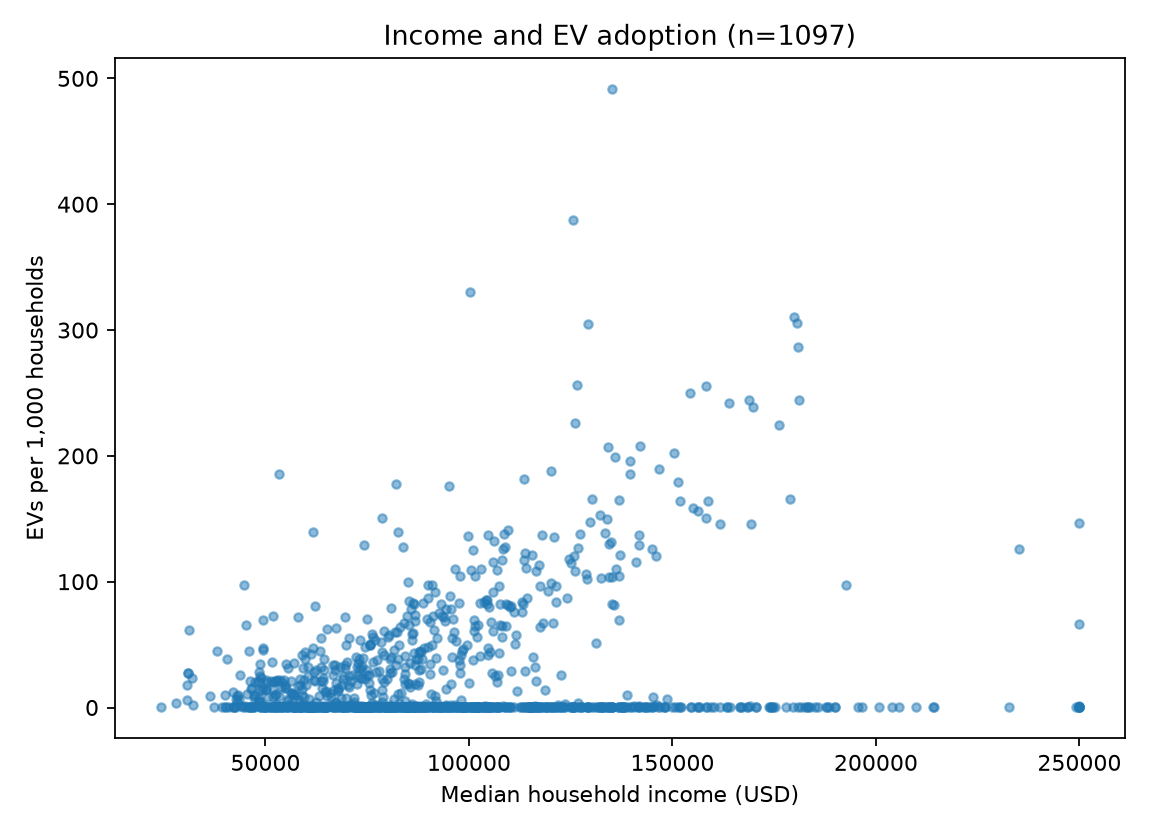

{'n': 1097, 'pearson_r': 0.244}


In [14]:
c1 = pe.plot_x_y(joined, "median_income", "ev_per_1000_households",
                 FIGS / "02_income_vs_ev.png", "Income and EV adoption",
                 "Median household income (USD)", "EVs per 1,000 households")
from IPython.display import Image, display
display(Image(filename=str(FIGS / "02_income_vs_ev.png")))
print(c1)


**Interpretation.** A **weak positive** association (Pearson r ~ 0.24, n ~ 1,097): higher-income codes tend to show somewhat higher adoption, but income explains only a small part of the variation. *Caveat:* association is not causal.

### Chart 3 — Public charging supply vs EV adoption

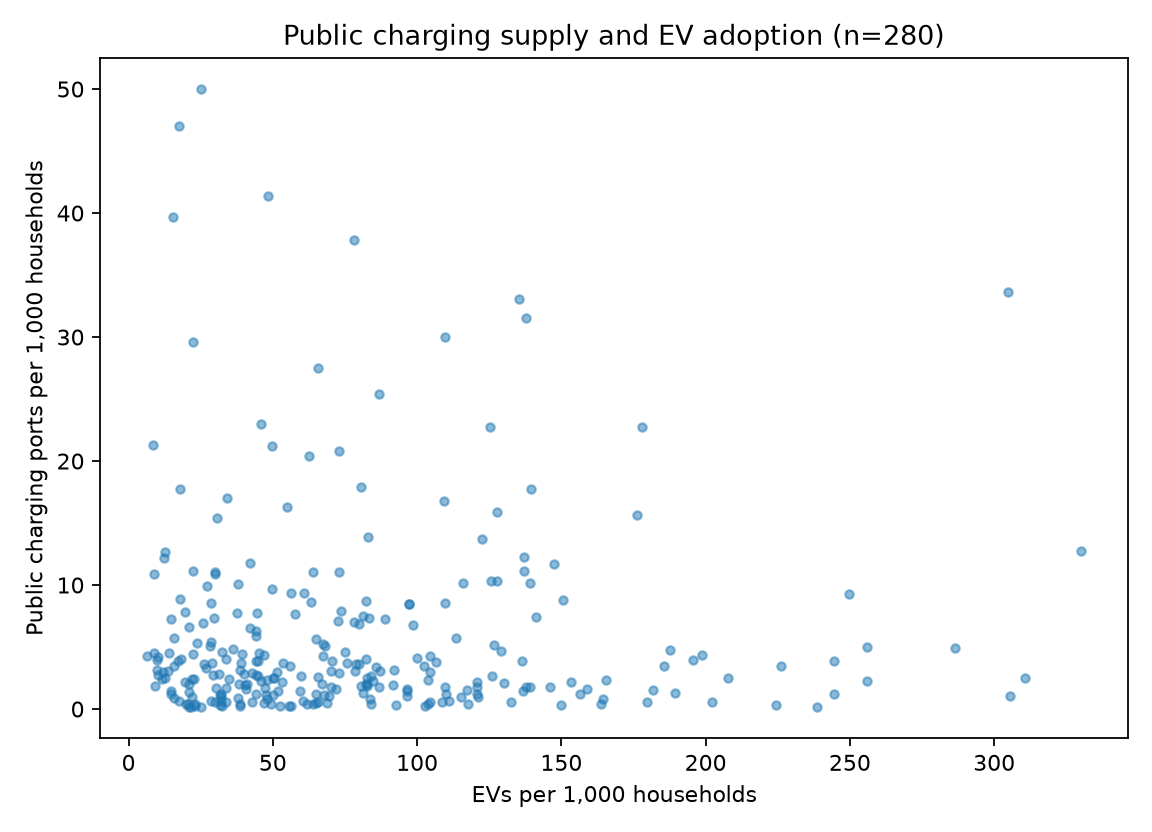

{'n': 280, 'pearson_r': 0.013}


In [15]:
c2 = pe.plot_x_y(joined, "ev_per_1000_households", "ports_per_1000_households",
                 FIGS / "03_supply_vs_adoption.png", "Public charging supply and EV adoption",
                 "EVs per 1,000 households", "Public charging ports per 1,000 households")
display(Image(filename=str(FIGS / "03_supply_vs_adoption.png")))
print(c2)


**Interpretation.** Essentially **no linear relationship** (Pearson r ~ 0.01, n ~ 280). Public port supply per household does not track adoption per household across codes. *Caveat:* port counts are not usage, and only ~25% of codes have a matched AFDC station.

### Chart 4 — Renter share vs public charging supply

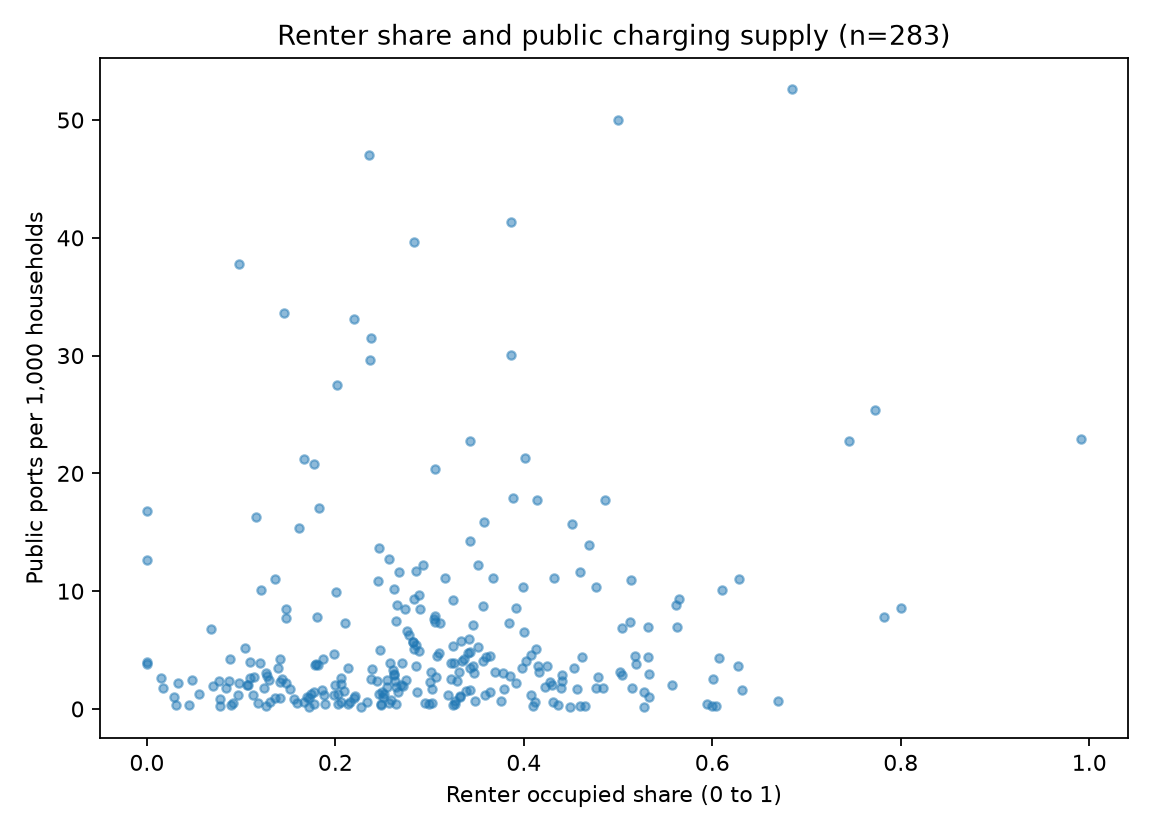

{'n': 283, 'pearson_r': 0.157}


In [16]:
c3 = pe.plot_x_y(joined, "renter_share", "ports_per_1000_households",
                 FIGS / "04_renter_vs_ports.png", "Renter share and public charging supply",
                 "Renter occupied share (0 to 1)", "Public ports per 1,000 households")
display(Image(filename=str(FIGS / "04_renter_vs_ports.png")))
print(c3)


**Interpretation.** A **weak positive** association (Pearson r ~ 0.16, n ~ 283): codes with more renters show slightly more public port supply, consistent with public charging partly substituting for home charging. *Caveat:* renter share is a community aggregate.

### Chart 5 — Join completeness / missingness

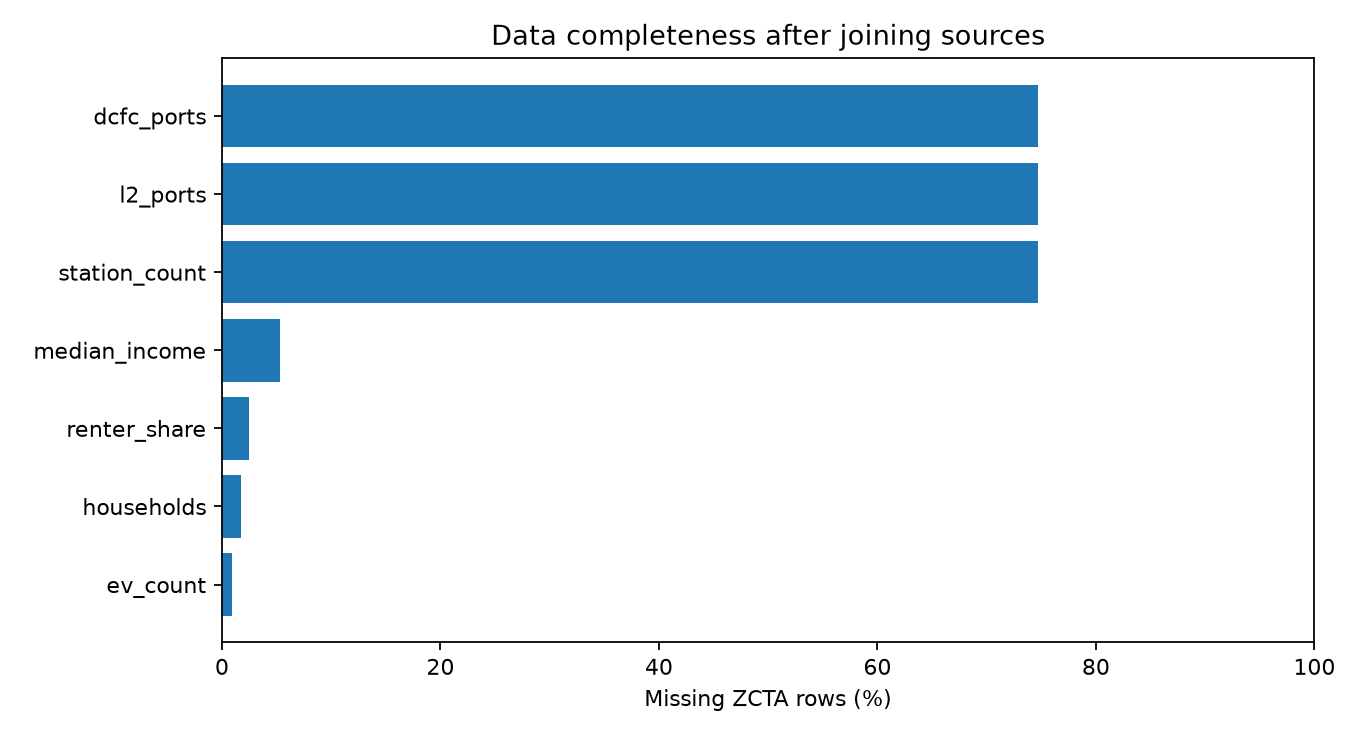

ev_count         0.009
households       0.017
median_income    0.053
renter_share     0.025
station_count    0.747
l2_ports         0.747
dcfc_ports       0.747


In [17]:
pe.quality_plot(joined, FIGS)
display(Image(filename=str(FIGS / "05_missingness.png")))
pct = joined[["ev_count", "households", "median_income", "renter_share",
              "station_count", "l2_ports", "dcfc_ports"]].isna().mean().round(3)
print(pct.to_string())


**Interpretation.** EV and demographic coverage is high (EV count missing for ~1% of codes, households ~2%), but charging-supply coverage is sparse: **about 75% of analysis codes have no matched AFDC station**, so station and port fields are mostly missing. This is a data-coverage gap, not demonstrated zero infrastructure — absent codes are not true zeros. *Caveat:* unmatched ZIPs and absent stations need independent interpretation before any underserved claim.